In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn import preprocessing, svm
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Reading the Dataset

In [10]:
df = pd.read_csv("bottle.csv", low_memory=False)
df_binary = df[["Salnty","T_degC"]]

df_binary.columns = [ 'Sal', 'Temp']

df_binary.head()

,Sal,Temp
0,33.440,10.50
1,33.440,10.46
2,33.437,10.46
3,33.420,10.45
4,33.421,10.45


# Exploring the data scatter

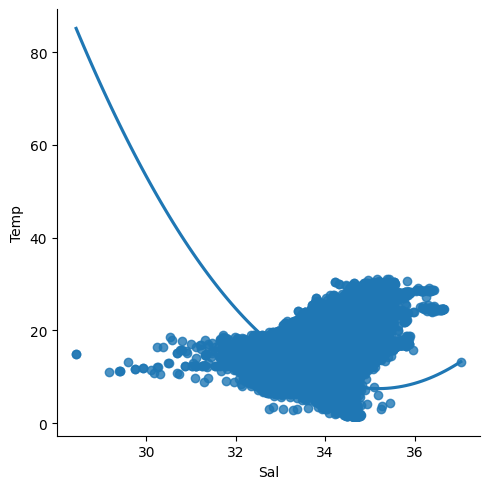

In [12]:
sns.lmplot(x="Sal", y="Temp", data=df_binary, order=2, ci=None)
plt.show()

# Data Cleaning

In [14]:
df_binary.ffill()

,Sal,Temp
0,33.4400,10.500
1,33.4400,10.460
2,33.4370,10.460
3,33.4200,10.450
4,33.4210,10.450
...,...,...
864858,33.4083,18.744
864859,33.4083,18.744
864860,33.4150,18.692
864861,33.4062,18.161


# Training the model

In [20]:
X = np.array(df_binary['Sal']).reshape(-1,1)
y = np.array(df_binary['Temp']).reshape(-1,1)

df.dropna(inplace=True)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25)

regr = LinearRegression()
regr.fit(X_train, y_train)
print(regr.score(X_test, y_test))

0.2090581780154116


# Exploring results

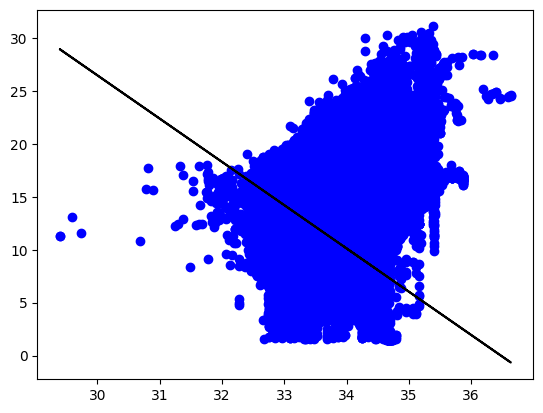

In [22]:
y_pred = regr.predict(X_test)
plt.scatter(X_test, y_test, color='b')
plt.plot(X_test, y_pred, color='k')

# Trying with a smaller dataset

In [23]:
df_binary500 = df_binary[:][:500]

df_binary500.ffill()

X = np.array(df_binary500['Sal']).reshape(-1,1)
y = np.array(df_binary500['Temp']).reshape(-1,1)

df_binary500.dropna(inplace=True)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25)

regr = LinearRegression()
regr.fit(X_train, y_train)
print(regr.score(X_test, y_test))

0.8376104541751893


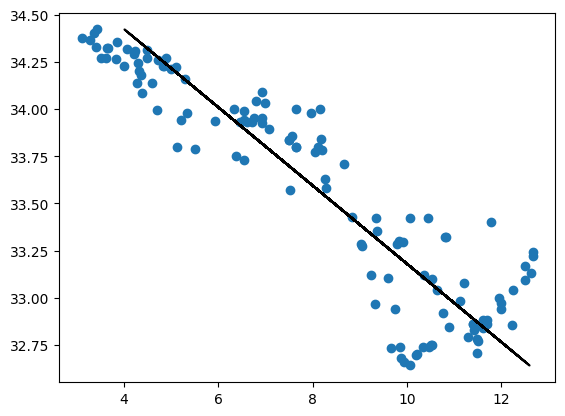

In [24]:
y_pred = regr.predict(X_test)
plt.scatter(y_test,X_test)
plt.plot(y_pred, X_test, color='k')